# Austin Animal Center: data quality investigation and EDA

**CMSE 830 midterm, Fall 2026.** This notebook is the working record behind `src/prepare_data.py` and `app.py`.
It does three things:

1. **First look** at the two raw files (intakes and outcomes) exactly as downloaded.
2. **Quality investigation**: each problem found, the evidence for it, and the decision taken.
3. **EDA** on the processed stay-level table that the app reads.

Run `python src/download_data.py` and `python src/prepare_data.py` from the project root first.
Charts here use matplotlib so they render on GitHub; the app uses Altair.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOG, CAT = "#2a78d6", "#eb6834"

intakes  = pd.read_csv("../data/raw/intakes.csv")
outcomes = pd.read_csv("../data/raw/outcomes.csv")
print("Intakes: ", intakes.shape)
print("Outcomes:", outcomes.shape)

Intakes:  (173812, 12)
Outcomes: (173775, 12)


## 1. First look

Every column arrives as text, including dates and ages.

In [2]:
intakes.head(3)

,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A521520,Nina,10/01/2013 07:51:00 AM,October 2013,Norht Ec in Austin (TX),Stray,Normal,Dog,Spayed Female,7 years,Border Terrier/Border Collie,White/Tan
1,A664235,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
2,A664236,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White


In [3]:
outcomes.head(3)

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green


In [4]:
def profile(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                         "missing_pct": (df.isna().mean() * 100).round(1), "unique": df.nunique()})
print("INTAKES"); display(profile(intakes))
print("OUTCOMES"); display(profile(outcomes))

INTAKES


,dtype,missing,missing_pct,unique
Animal ID,str,0,0.0,156287
Name,str,49991,28.8,29774
DateTime,str,0,0.0,119722
MonthYear,str,0,0.0,140
Found Location,str,0,0.0,70183
Intake Type,str,0,0.0,6
Intake Condition,str,0,0.0,20
Animal Type,str,0,0.0,5
Sex upon Intake,str,1,0.0,5
Age upon Intake,str,0,0.0,55


OUTCOMES


,dtype,missing,missing_pct,unique
Animal ID,str,0,0.0,156237
Date of Birth,str,0,0.0,8692
Name,str,49784,28.6,29756
DateTime,str,0,0.0,146382
MonthYear,str,0,0.0,140
Outcome Type,str,46,0.0,11
Outcome Subtype,str,94115,54.2,26
Animal Type,str,0,0.0,5
Sex upon Outcome,str,1,0.0,5
Age upon Outcome,str,9,0.0,55


Three missingness patterns already stand out, and they are different kinds of missing:

- `Name` is missing for ~29% of rows in both files.
- `Outcome Subtype` is missing for 54% of outcomes.
- `Outcome Type` is missing for only 46 outcomes.

We come back to each below.

In [5]:
print("Exact duplicate rows  - intakes:", intakes.duplicated().sum(), " outcomes:", outcomes.duplicated().sum())
print("Same animal, same timestamp - intakes:", intakes.duplicated(["Animal ID", "DateTime"]).sum(),
      " outcomes:", outcomes.duplicated(["Animal ID", "DateTime"]).sum())

Exact duplicate rows  - intakes: 36  outcomes: 26
Same animal, same timestamp - intakes: 42  outcomes: 27


## 2. Quality investigation

### 2.1 Two files, two date formats

In [6]:
pattern = lambda s: s.str.replace(r"\d", "9", regex=True)
print("Intake date patterns:");  print(pattern(intakes["DateTime"]).value_counts(), "\n")
print("Outcome date patterns:"); print(pattern(outcomes["DateTime"]).value_counts())

Intake date patterns:


DateTime
99/99/9999 99:99:99 PM    125689
99/99/9999 99:99:99 AM     48123
Name: count, dtype: int64 

Outcome date patterns:


DateTime
9999-99-99T99:99:99          170191
9999-99-99T99:99:99-99:99      3584
Name: count, dtype: int64


In [7]:
has_offset = outcomes["DateTime"].str.contains(r"[+-]\d\d:\d\d$", regex=True)
print("Outcome rows with a UTC offset:", has_offset.sum())
print("...of which stamped exactly midnight:", outcomes.loc[has_offset, "DateTime"].str.contains("T00:00:00").sum())
outcomes.loc[has_offset, "DateTime"].head()

Outcome rows with a UTC offset: 3584
...of which stamped exactly midnight: 3584


0    2013-12-02T00:00:00-05:00
1    2014-02-22T00:00:00-05:00
2    2014-04-07T00:00:00-05:00
3    2014-05-16T00:00:00-05:00
4    2014-06-10T00:00:00-05:00
Name: DateTime, dtype: str

**Decision.** Every offset row is a date-only record (midnight). Parse each file with its own explicit format,
strip the offset, and treat all timestamps as Austin local time, which the intake file already is.

In [8]:
intakes["dt"]  = pd.to_datetime(intakes["DateTime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
outcomes["dt"] = pd.to_datetime(outcomes["DateTime"].str.replace(r"[+-]\d\d:\d\d$", "", regex=True),
                                format="%Y-%m-%dT%H:%M:%S", errors="coerce")
print("Unparsed:", intakes["dt"].isna().sum(), outcomes["dt"].isna().sum())
print("Intakes :", intakes["dt"].min(), "->", intakes["dt"].max())
print("Outcomes:", outcomes["dt"].min(), "->", outcomes["dt"].max())
print("Outcomes with no time of day (midnight):", (outcomes["dt"].dt.time.astype(str) == "00:00:00").sum())

Unparsed: 0 0
Intakes : 2013-10-01 07:51:00 -> 2025-05-04 23:44:00
Outcomes: 2013-10-01 09:31:00 -> 2025-05-05 07:22:00


Outcomes with no time of day (midnight): 3788


### 2.2 Which animals? Dogs and cats only

In [9]:
print(intakes["Animal Type"].value_counts(), "\n")
other = outcomes[outcomes["Animal Type"] == "Other"]
print("Outcome mix for 'Other':"); print(other["Outcome Type"].value_counts(normalize=True).round(3).head(5))
print("\nMost common 'Other' breeds:", other["Breed"].value_counts().head(5).to_dict())

Animal Type
Dog          94608
Cat          69324
Other         8968
Bird           878
Livestock       34
Name: count, dtype: int64 

Outcome mix for 'Other':
Outcome Type
Euthanasia    0.659
Transfer      0.129
Adoption      0.112
Disposal      0.065
Died          0.026
Name: proportion, dtype: float64

Most common 'Other' breeds: {'Bat': 2356, 'Bat Mix': 1756, 'Raccoon': 826, 'Guinea Pig': 552, 'Raccoon Mix': 539}


**Decision.** "Other" is mostly bats and raccoons brought in for rabies testing and euthanised within hours.
They are not part of an adoption question and would distort every summary, so the analysis keeps dogs and cats
(94% of rows). Birds and livestock are too few to summarise.

### 2.3 Ages are text, and some are impossible

In [10]:
age = intakes["Age upon Intake"]
print("Distinct age strings:", age.nunique())
print(age.value_counts().head(12))
print("\nStrings that are not '<positive number> <unit>':")
print(age[~age.str.match(r"^[1-9]\d* (year|years|month|months|week|weeks|day|days)$")].value_counts())

Distinct age strings: 55
Age upon Intake
1 year      28294
2 years     28033
1 month     18203
2 months    10432
3 years      9610
4 weeks      6324
4 years      5842
5 years      5187
3 weeks      5124
3 months     4924
4 months     4787
5 months     4377
Name: count, dtype: int64

Strings that are not '<positive number> <unit>':
Age upon Intake
0 years     1268
-1 years       6
-3 years       2
-2 years       1
-4 years       1
Name: count, dtype: int64


In [11]:
# What does '0 years' mean?  Compare with the date of birth recorded in the outcomes file.
dob = pd.to_datetime(outcomes.drop_duplicates("Animal ID").set_index("Animal ID")["Date of Birth"], errors="coerce")
zero = intakes[age == "0 years"].copy()
zero["dob"] = zero["Animal ID"].map(dob)
same_day = (zero["dob"].dt.normalize() == zero["dt"].dt.normalize())
print(f"'0 years' rows: {len(zero):,}; date of birth == intake date for {same_day.mean():.0%} of them")

'0 years' rows: 1,268; date of birth == intake date for 80% of them


**Decision.** `0 years` is a placeholder: in 80% of cases the date of birth was simply set to the intake date, i.e.
nobody estimated an age. Negative ages come from a date of birth typed in *after* the intake. Both become
**unknown** (NaN) in `parse_age_to_days`, and "Unknown" is kept as its own age group rather than imputed.
Other ages are converted to days (year = 365.25, month = 30.44, week = 7) and binned into four bands.

### 2.4 Repeat visits: why a plain join is wrong

In [12]:
visits = intakes["Animal ID"].value_counts()
print(f"Unique animals: {visits.size:,}")
print(f"Animals with more than one intake: {(visits > 1).sum():,}")
print(f"Most intakes for one animal: {visits.max()}")
naive = intakes[["Animal ID", "dt"]].merge(outcomes[["Animal ID", "dt"]], on="Animal ID", suffixes=("_in", "_out"))
print(f"\nNaive join on Animal ID: {len(naive):,} rows for {len(intakes):,} intakes")
print(f"Pairs where the outcome is BEFORE the intake: {(naive['dt_out'] < naive['dt_in']).sum():,}")

Unique animals: 156,287
Animals with more than one intake: 13,487
Most intakes for one animal: 33

Naive join on Animal ID: 221,246 rows for 173,812 intakes
Pairs where the outcome is BEFORE the intake: 24,912


**Decision.** Build one event table per animal, sorted by time; each intake opens a new *stay* and the first
outcome after it closes that stay. This is implemented in `src/prepare_data.py` (step 6) with
`groupby().cumsum()` on the intake flag to number stays and `cumcount()` to find the first outcome in each.

### 2.5 Three kinds of missingness

In [13]:
print("Share of intakes with NO name, by intake type (informative: a missing name means a stray):")
print(intakes.groupby("Intake Type")["Name"].apply(lambda s: round(s.isna().mean(), 3)), "\n")
print("Share of outcomes with NO subtype, by outcome type (structural: most types have no subtype):")
print(outcomes.groupby("Outcome Type")["Outcome Subtype"].apply(lambda s: round(s.isna().mean(), 3)))
print("\nOutcomes with no Outcome Type at all (genuinely missing):", outcomes["Outcome Type"].isna().sum())

Share of intakes with NO name, by intake type (informative: a missing name means a stray):
Intake Type
Abandoned             0.197
Euthanasia Request    0.106
Owner Surrender       0.098
Public Assist         0.105
Stray                 0.325
Wildlife              0.970
Name: Name, dtype: float64 

Share of outcomes with NO subtype, by outcome type (structural: most types have no subtype):
Outcome Type
Adoption           0.782
Died               0.075
Disposal           0.937
Euthanasia         0.026
Lost               1.000
Missing            0.217
Relocate           1.000
Return to Owner    0.989
Rto-Adopt          1.000
Stolen             1.000
Transfer           0.000
Name: Outcome Subtype, dtype: float64

Outcomes with no Outcome Type at all (genuinely missing): 46


**Decision.** None of this is missing at random, so nothing is imputed. The missing name becomes a feature
("arrived with a name"), the subtype is left as is, and the 46 type-less outcomes are grouped as "Other / unknown".

### 2.6 Category labels that changed over time

In [14]:
cond = intakes.groupby("Intake Condition")["dt"].agg(rows="size", first_seen="min").sort_values("rows", ascending=False)
cond["first_seen"] = cond["first_seen"].dt.date
cond

,rows,first_seen
Intake Condition,,
Normal,147141,2013-10-01
Injured,10805,2013-10-01
Sick,7939,2013-10-02
Nursing,3878,2013-10-01
Neonatal,1971,2020-11-12
Medical,614,2019-09-17
Aged,525,2013-10-09
Other,353,2013-10-05
Pregnant,170,2013-10-09


**Decision.** Several labels were introduced late and have only a handful of rows. They are grouped into seven
groups by what they mean for the animal (see `CONDITION_GROUPS` in `src/prepare_data.py`).

## 3. The processed table

`src/prepare_data.py` applies every decision above and writes one row per stay. The pipeline also writes
`quality_report.json` so the app never hard-codes a number.

In [15]:
stays = pd.read_parquet("../data/processed/stays.parquet")
with open("../data/processed/quality_report.json") as fh:
    report = json.load(fh)
print(stays.shape)
print(json.dumps({k: report[k] for k in ["naive_join", "matching", "stays"]}, indent=2))
stays.head()

(163895, 31)
{
  "naive_join": {
    "rows": 211165,
    "pairs_with_outcome_before_intake": 24776
  },
  "matching": {
    "outcomes_before_first_intake": 1443,
    "extra_outcomes_in_same_stay": 78
  },
  "stays": {
    "total": 163895,
    "with_outcome": 162358,
    "open": 1537,
    "open_by_intake_year": {
      "2013": 2,
      "2014": 49,
      "2015": 64,
      "2016": 56,
      "2017": 115,
      "2018": 110,
      "2019": 106,
      "2020": 27,
      "2021": 15,
      "2022": 20,
      "2023": 28,
      "2024": 145,
      "2025": 800
    },
    "animals": 146450,
    "animals_with_repeat_stays": 13421,
    "max_stays_one_animal": 33,
    "negative_los": 0,
    "los_over_365": 568
  }
}


,animal_id,stay_number,species,intake_dt,outcome_dt,has_outcome,los_days,los_lower_bound_days,intake_type,intake_condition_raw,condition_group,age_text,age_days,age_years,age_group,...,fixed_at_intake,fixed_at_outcome,arrived_with_name,breed_raw,primary_breed,is_mix,color_raw,primary_color,intake_year,intake_month,season,outcome_type_raw,outcome_subtype,outcome_group,adopted
0,A521520,1,Dog,2013-10-01 07:51:00,2013-10-01 15:39:00,True,0.325000,0.325000,Stray,Normal,Normal,7 years,2556.75,7.000000,7+ years,...,Fixed,Fixed,True,Border Terrier/Border Collie,Border Terrier,True,White/Tan,White,2013,10,Fall,Return to Owner,NaN,Return to owner,False
1,A664235,1,Cat,2013-10-01 08:33:00,2013-10-01 10:39:00,True,0.087500,0.087500,Stray,Normal,Normal,1 week,7.00,0.019165,Under 6 months,...,Unknown,Unknown,False,Domestic Shorthair Mix,Domestic Shorthair,True,Orange/White,Orange,2013,10,Fall,Transfer,Partner,Transfer to partner,False
2,A664236,1,Cat,2013-10-01 08:33:00,2013-10-01 10:44:00,True,0.090972,0.090972,Stray,Normal,Normal,1 week,7.00,0.019165,Under 6 months,...,Unknown,Unknown,False,Domestic Shorthair Mix,Domestic Shorthair,True,Orange/White,Orange,2013,10,Fall,Transfer,Partner,Transfer to partner,False
3,A664237,1,Cat,2013-10-01 08:33:00,2013-10-01 10:44:00,True,0.090972,0.090972,Stray,Normal,Normal,1 week,7.00,0.019165,Under 6 months,...,Unknown,Unknown,False,Domestic Shorthair Mix,Domestic Shorthair,True,Orange/White,Orange,2013,10,Fall,Transfer,Partner,Transfer to partner,False
4,A664233,1,Dog,2013-10-01 08:53:00,2013-10-01 15:33:00,True,0.277778,0.277778,Stray,Injured,Injured,3 years,1095.75,3.000000,2 - 7 years,...,Intact,Intact,True,Pit Bull Mix,Pit Bull,True,Blue/White,Blue,2013,10,Fall,Euthanasia,Suffering,Euthanasia,False


In [16]:
# Check the matching on one animal with three stays
example = stays["animal_id"].value_counts().pipe(lambda s: s[s == 3]).index.min()
stays.loc[stays["animal_id"] == example, ["animal_id", "stay_number", "intake_dt", "intake_type", "outcome_dt", "outcome_group", "los_days"]]

,animal_id,stay_number,intake_dt,intake_type,outcome_dt,outcome_group,los_days
6467,A006100,1,2014-03-07 14:26:00,Public Assist,2014-03-08 17:10:00,Return to owner,1.113889
20995,A006100,2,2014-12-19 10:21:00,Public Assist,2014-12-20 16:35:00,Return to owner,1.259722
71407,A006100,3,2017-12-07 14:07:00,Stray,NaT,No outcome recorded,NaN


In [17]:
assert (stays["los_days"].dropna() >= 0).all(), "negative length of stay"
assert stays["stay_number"].ge(1).all()
print("No negative stays; every stay numbered. Open stays:", (~stays["has_outcome"]).sum())

No negative stays; every stay numbered. Open stays: 1537


## 4. EDA

### 4.1 Length of stay is heavily skewed, so use medians

count    162358.0
mean         22.0
std          49.4
min           0.0
25%           2.4
50%           6.2
75%          21.3
90%          57.1
99%         220.0
max        1912.9
Name: los_days, dtype: float64


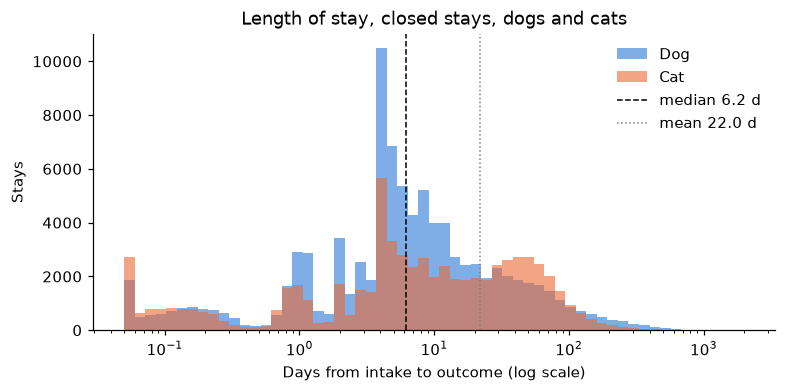

In [18]:
closed = stays[stays["has_outcome"]]
print(closed["los_days"].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.logspace(np.log10(0.05), np.log10(2000), 60)
for sp, c in [("Dog", DOG), ("Cat", CAT)]:
    ax.hist(closed.loc[closed["species"] == sp, "los_days"].clip(lower=0.05), bins=bins, alpha=0.6, color=c, label=sp)
ax.set_xscale("log"); ax.set_xlabel("Days from intake to outcome (log scale)"); ax.set_ylabel("Stays")
ax.axvline(closed["los_days"].median(), color="k", lw=1, ls="--", label=f"median {closed['los_days'].median():.1f} d")
ax.axvline(closed["los_days"].mean(), color="grey", lw=1, ls=":", label=f"mean {closed['los_days'].mean():.1f} d")
ax.legend(frameon=False); ax.set_title("Length of stay, closed stays, dogs and cats"); plt.show()

### 4.2 Days to adoption by age band and species

median        count       
species               Cat   Dog    Cat    Dog
age_group                                    
Under 6 months       30.0   6.2  24006  14073
6 months - 2 years   12.2   8.8   4702  14494
2 - 7 years          19.0  14.1   4894  15521
7+ years             27.1  20.9   1568   2895
Unknown              78.5  63.0    262    178

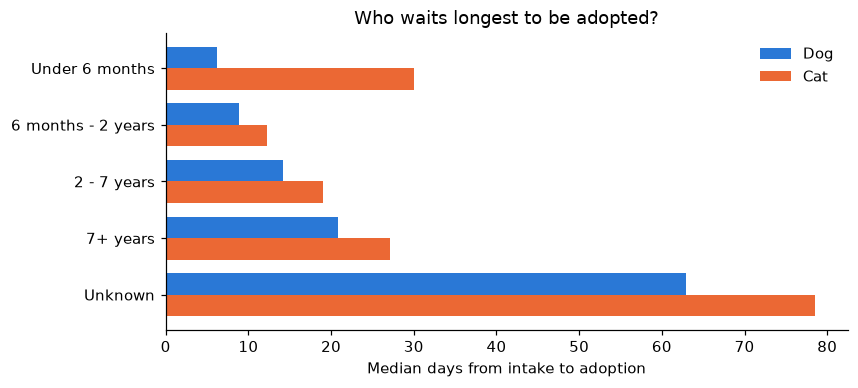

In [19]:
adopted = stays[stays["adopted"]]
order = ["Under 6 months", "6 months - 2 years", "2 - 7 years", "7+ years", "Unknown"]
tab = adopted.pivot_table(index="age_group", columns="species", values="los_days", aggfunc=["median", "count"], observed=True).reindex(order)
display(tab.round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
med = tab["median"]
x = np.arange(len(order)); w = 0.38
ax.barh(x - w/2, med["Dog"], w, color=DOG, label="Dog"); ax.barh(x + w/2, med["Cat"], w, color=CAT, label="Cat")
ax.set_yticks(x, order); ax.invert_yaxis(); ax.set_xlabel("Median days from intake to adoption"); ax.legend(frameon=False)
ax.set_title("Who waits longest to be adopted?"); plt.show()

### 4.3 Outcome mix: a short stay is not always good news

In [20]:
closed = stays[stays["has_outcome"]]
mix = (closed.groupby(["species", "age_group"], observed=True)["outcome_group"].value_counts(normalize=True)
       .unstack().reindex(columns=["Adoption", "Transfer to partner", "Return to owner", "Euthanasia", "Died in care", "Other / unknown"]))
mix.round(3)

outcome_group               Adoption  Transfer to partner  Return to owner  Euthanasia  Died in care  Other / unknown
species age_group                                                                                                    
Cat     2 - 7 years            0.401                0.401            0.123       0.059         0.015            0.001
        6 months - 2 years     0.434                0.465            0.059       0.031         0.010            0.001
        7+ years               0.413                0.267            0.172       0.127         0.020            0.001
        Under 6 months         0.584                0.367            0.007       0.024         0.018            0.001
        Unknown                0.413                0.469            0.009       0.024         0.082            0.003
Dog     2 - 7 years            0.433                0.200            0.333       0.030         0.004            0.001
        6 months - 2 years     0.568                0.198            0.218       0.013         0.002            0.001
        7+ years               0.289                0.178            0.470       0.055         0.007            0.000
        Under 6 months         0.643                0.275            0.062       0.010         0.009            0.000
        Unknown                0.337                0.562            0.045       0.008         0.047              NaN

### 4.4 Breed (dogs) and colour

In [21]:
dogs_ad = adopted[adopted["species"] == "Dog"]
by_breed = dogs_ad.groupby("primary_breed")["los_days"].agg(median="median", n="size")
display(by_breed[by_breed["n"] >= 800].sort_values("median", ascending=False).round(1))
pit = dogs_ad["breed_raw"].str.contains("Pit Bull|Staffordshire|American Bulldog")
print(f"Pit-bull-type dogs: median {dogs_ad[pit]['los_days'].median():.1f} d (n={pit.sum():,}) vs other dogs {dogs_ad[~pit]['los_days'].median():.1f} d")
for sp in ["Dog", "Cat"]:
    a = adopted[adopted["species"] == sp]; black = a["primary_color"] == "Black"
    print(f"{sp}s - black: {a[black]['los_days'].median():.1f} d, other colours: {a[~black]['los_days'].median():.1f} d")

,median,n
primary_breed,,
Pit Bull,29.2,6458
Boxer,13.1,930
Labrador Retriever,11.0,7469
Australian Cattle Dog,10.9,1883
German Shepherd,10.2,4025
Great Pyrenees,9.1,811
Border Collie,8.4,1024
Siberian Husky,8.2,1177
Chihuahua Shorthair,6.1,4918


Pit-bull-type dogs: median 28.2 d (n=8,645) vs other dogs 8.0 d
Dogs - black: 9.2 d, other colours: 9.3 d
Cats - black: 29.2 d, other colours: 24.2 d


### 4.5 Trend by year, and the censoring artefact

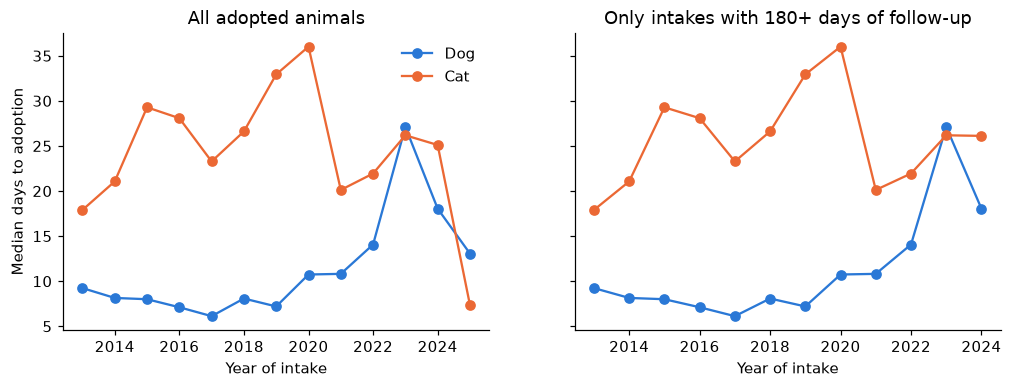

The 2025 'improvement' on the left disappears on the right: only fast adoptions from 2025 have happened yet.


In [22]:
as_of = pd.Timestamp(report["as_of_date"])
yearly_all = adopted.pivot_table(index="intake_year", columns="species", values="los_days", aggfunc="median", observed=True)
fair = adopted[adopted["intake_dt"] <= as_of - pd.Timedelta(days=180)]
yearly_fair = fair.pivot_table(index="intake_year", columns="species", values="los_days", aggfunc="median", observed=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, y, title in [(axes[0], yearly_all, "All adopted animals"), (axes[1], yearly_fair, "Only intakes with 180+ days of follow-up")]:
    ax.plot(y.index, y["Dog"], marker="o", color=DOG, label="Dog"); ax.plot(y.index, y["Cat"], marker="o", color=CAT, label="Cat")
    ax.set_title(title); ax.set_xlabel("Year of intake")
axes[0].set_ylabel("Median days to adoption"); axes[0].legend(frameon=False); plt.show()
print("The 2025 'improvement' on the left disappears on the right: only fast adoptions from 2025 have happened yet.")

## 5. Notes carried into the app

- Unit of analysis: one **stay** (intake matched to its outcome). 163,895 stays for 146,450 dogs and cats.
- Medians and quartiles everywhere (mean 22 d vs median 6 d).
- Default measure is **days to adoption** for adopted animals; "any outcome" is dominated by same-day returns to owner.
- Unfinished stays are **censored, not dropped**; the app's still-waiting curves use Kaplan-Meier.
- No imputation (missingness is informative or structural), no outlier removal (long stays are real), no scaling or
  encoding (no model yet). Each is stated as a decision in the app's *Data & decisions* tab.